# Decode the Bioreactor: forecasting a fed-batch culture with machine learning and process knowledge

**Team 6 final model, leaderboard mean MAPE 6.995** (VCD 6.609 · TCD 6.475 · substrate 6.873 · byproduct 8.022)

This notebook rebuilds the Team 6 submission to the *Decode the Bioreactor* challenge and explains every step: what we did, why it works, and how we validated it. It is written as teaching material for a course on machine learning in pharmaceutical process development.

**What you will learn**

1. How the evaluation metric (MAPE) should shape the loss function, the way models are combined and the point forecast itself.
2. How to validate on small, grouped data (49 batches) without fooling yourself, and why a 12-batch leaderboard is noisy.
3. Why process *inputs* that are set by controllers are "hidden sensors" of the process state.
4. How to combine mechanistic (mass-balance, kinetic) models with machine learning.
5. How to diagnose what is left: a batch-level effect that no input records.

**Structure:** 1 Problem · 2 Metric · 3 Validation · 4 Hidden sensors · 5 Cell densities: kinetic model + ensemble · 6 Byproduct ensemble · 7 Corrections · 8 Final forecast · 9 Results · 10 What did not work · 11 Exercises · 12 Submission

**How to run:** from this folder, run all cells (about 30 s). Helper code for the notebook is in `src/dtb/` (data, metrics, cross-validation, pipeline, plots). The research code it calls is in `src/research/` and the team C11 library in `src/c11/`. `README.md` lists every file, and `docs/RESEARCH_LOG.md` has the full trial history.

In [1]:
import sys
sys.path.insert(0, "src")
import numpy as np, pandas as pd
from IPython.display import display
from dtb import data, metrics, cv, pipeline, plots

plots.style()
pd.set_option("display.precision", 3)
raw = data.load_raw()

## 1. The problem

A **fed-batch** culture is the workhorse of biopharmaceutical production: cells (typically CHO cells making a therapeutic protein) grow in a bioreactor for about two weeks, and nutrients are added during the run instead of all at the start. Four quantities are tracked by daily samples:

| Target | Meaning | Typical analogue |
|---|---|---|
| **VCD** | viable cell density | living cells per volume |
| **TCD** | total cell density | living + dead cells (so TCD ≥ VCD) |
| **substrate** | main carbon source | glucose |
| **byproduct** | metabolic waste product | lactate (an acid) |

The data are anonymised, but the dynamics behave like glucose and lactate, and that analogy guides the modelling.

**The task.** For each test batch we get *one* measured sample (day 0), the complete **feed schedule** (four feeds, every dose and time), and the **culture volume** at every sampling time. We must forecast all four targets at the 13 later sampling times. This is long-horizon forecasting from a single point, not interpolation: almost everything we know about a test batch after day 0 must come from its inputs.

,count
training batches,49.0
test batches,12.0
measured samples (training),698.0
samples to forecast,156.0
feed events,2004.0
run length (days),13.0


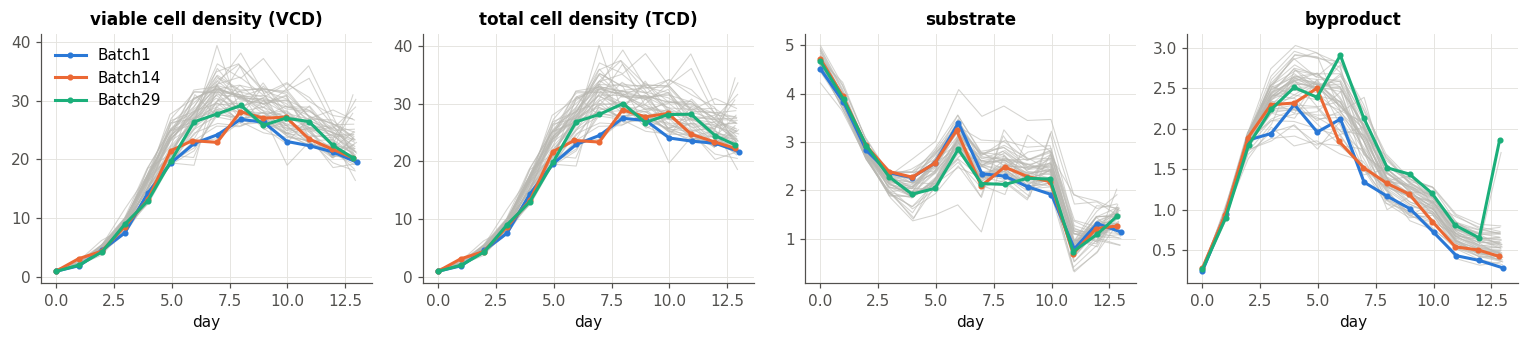

In [2]:
display(data.overview(raw).to_frame("count"))
plots.plot_batches(raw);

Batches start similarly but drift apart: the spread of the grey curves on day 13 is what the model has to explain. Batch29 (aqua) is one of two batches whose byproduct shoots up on the last day; we come back to it in Section 7.

Below is everything the model sees about a test batch after day 0: feed events and volume.

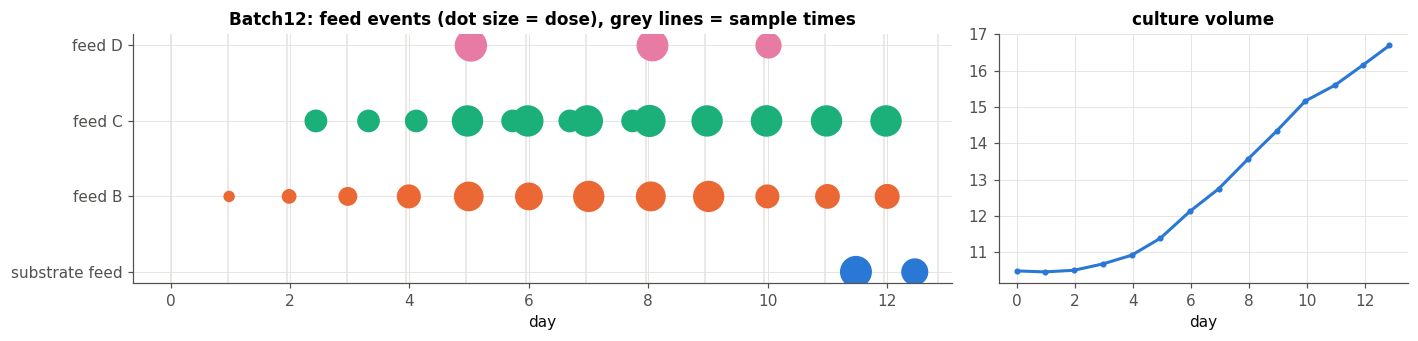

In [3]:
plots.plot_feeds(raw, "Batch12");

Note the structure. Feed B is dosed about one hour after each daily sample. The substrate feed comes as boluses at about days 11.5 and 12.5 at two possible dose levels. Feed D comes three times. Volume rises with the feeds, but also with base added by the pH controller, which is not listed as a feed. Section 4 shows that these details carry information about the culture.

## 2. The metric decides the model

The score is the mean absolute percentage error, averaged over the four targets:

$$\text{MAPE} = \frac{100}{N}\sum_{i=1}^{N}\frac{|\hat y_i - y_i|}{y_i}.$$

Each point is weighted by $1/y_i$, so **small values dominate the score**. A 0.1 error costs 20% at $y = 0.5$ but 3% at $y = 3$. The small values are the day-1 cell densities, substrate late in the run and byproduct early in the run.

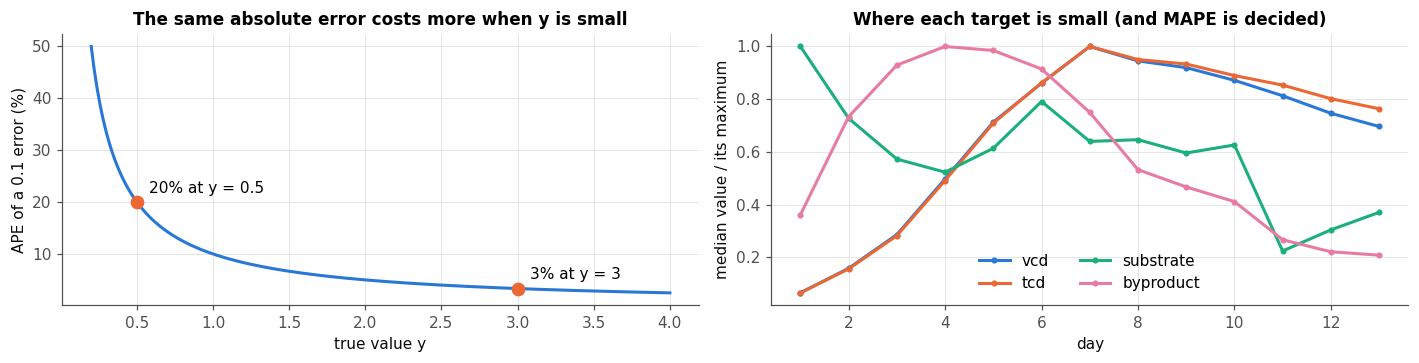

In [4]:
plots.plot_mape_weight(raw);

### Three consequences

**(a) Train on the metric.** A model trained with squared error (RMSE) spends its capacity on the large values, which MAPE barely counts. Two equivalent fixes:
- weight absolute error by $1/y$, which *is* MAPE; tree ensembles in scikit-learn accept `criterion="absolute_error"` with `sample_weight = 1/y`;
- work in log space: $|\log\hat y - \log y| \approx |\hat y - y|/y$ for small errors, so a model of $\log y$ fits relative error.

With the same model, switching from squared error to a MAPE-weighted loss took our team-CV MAPE from 8.79 to 8.33, better in 49 of 50 folds. It was the largest single early gain.

**(b) Combine in log space.** For the same reason we average ensemble members geometrically, $\hat y = \exp(\frac{1}{M}\sum_m \log \hat y_m)$, so every member's *relative* error counts equally.

**(c) The best point forecast is not the mean.** For a predictive distribution $p(y)$, the forecast that minimises the expected loss is:

| Loss | Optimal point forecast |
|---|---|
| squared error | mean |
| absolute error | median |
| absolute percentage error | median of the reweighted density $\propto p(y)/y$ |

For a log-normal $p(y)$ with log-scale $\sigma$, the MAPE-optimal forecast is $e^{\mu-\sigma^2}$: slightly *below* the median $e^{\mu}$. Here is the same idea on real data: the best single number to forecast day-1 VCD under each loss.

In [5]:
s = data.samples(raw)
metrics.best_constants(s.loc[s.day == 1, "vcd"]).to_frame("day-1 VCD")

,day-1 VCD
mean (best for squared error),2.151
median (best for absolute error),2.057
1/y-weighted median (best for MAPE),2.038
check: grid minimum of MAPE,2.038


The 1/y-weighted median is below the plain median, and a brute-force grid search confirms it minimises MAPE. Our errors are small ($\sigma \approx 0.1$, so $e^{-\sigma^2} \approx 0.99$), and an explicit down-scaling of the final byproduct forecast did not help in cross-validation. Still, keep the principle in mind: **the metric defines what "the best forecast" means.**

## 3. Validation on 49 batches

With 49 training batches, validation design matters as much as the model.

- **Group by batch.** Samples from the same batch are strongly correlated. A random split of *samples* leaks information about a batch's trajectory into its own test points. We always hold out **whole batches**, as the leaderboard does.
- **Repeat.** One split of 49 batches is noisy. Our team protocol is 5-fold cross-validation repeated with 2 different shuffles: 10 train/test fits, and every batch held out twice.
- **Compare in pairs.** Two models are compared batch by batch, on the *same* held-out batches. We report the mean difference, its standard error and the share of batches that improve. A paired difference is far less noisy than the difference of two overall scores.
- **Nest the tuning.** Any correction learned from errors (Section 7) is learned on the training folds only and then applied to the held-out fold.
- **Count your looks.** Every comparison you run on the same folds is a chance to over-fit them. Our first fixed 10-batch benchmark became over-used, and its results stopped carrying over to new data. That is why we moved to repeated full cross-validation.

The out-of-fold predictions of all byproduct members are cached (refitting everything takes hours):

In [6]:
T = cv.load_oof()
print(f"{len(T)} out-of-fold rows = 2 splits × {T.batch_id.nunique()} batches × 13 samples")
T.groupby(["split", "fold"]).batch_id.nunique().unstack().rename_axis(index="split", columns="fold")

1274 out-of-fold rows = 2 splits × 49 batches × 13 samples


fold,1,2,3,4,5
split,,,,,
0,10,10,10,10,9
1,10,10,10,10,9


**How noisy is the leaderboard?** It scores only 12 batches. Using our out-of-fold errors, we can simulate the spread of a model difference when only 12 random batches are scored:

In [7]:
base = data.base_volume_profile(raw)
table, steps = cv.ablation(T, base)
final_oof, before_offset = steps["+ base-volume batch offset (final)"], steps["+ amount curve (A6)"]
sd = cv.leaderboard_noise(T, final_oof, before_offset)
print(f"base-volume step: CV gain {table.loc['+ base-volume batch offset (final)', 'change']:+.3f}, "
      f"12-batch leaderboard noise ±{sd:.2f} (one standard deviation)")

base-volume step: CV gain -0.077, 12-batch leaderboard noise ±0.13 (one standard deviation)


On 12 batches the noise is larger than the effect, so a single leaderboard result cannot confirm or reject a small change. We used the leaderboard as a final sanity check and **cross-validation for decisions**. That is also why the last tweak (Section 5, a heavier v4 weight) should be read as a lucky bet that happened to go our way, not as evidence.

## 4. Hidden sensors: controllers reveal the state

In a real bioprocess, some "inputs" are not fixed in advance. Controllers or operators set them **after looking at the culture**. A manipulated variable that depends on the state carries information about that state. This is the idea behind *soft sensors* in process analytical technology (PAT): inferring an unmeasured quantity from the ones you have.

### 4.1 The substrate-feed controller

Each late substrate bolus comes in one of two doses per volume. Plotting the dose against the substrate measured at the preceding sample shows the rule:

substrate < 0.966,False,True
high dose,,
False,65,0
True,0,40


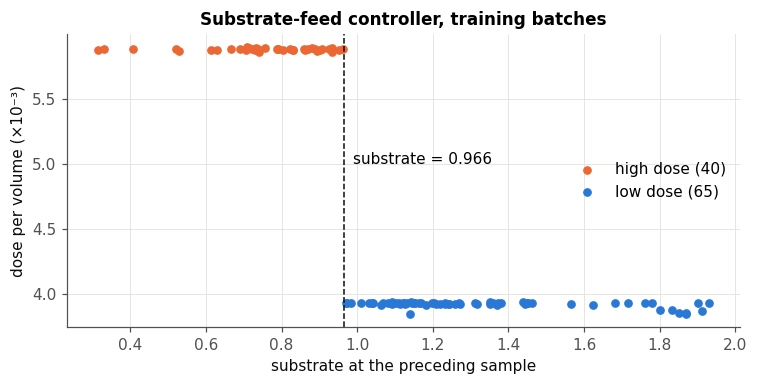

In [8]:
ev = data.substrate_controller_events(raw)
plots.plot_controller(ev)
train_ev = ev[~ev.test]
pd.crosstab(train_ev.high_dose, train_ev.substrate_at_sample < data.SUBSTRATE_THRESHOLD,
            rownames=["high dose"], colnames=[f"substrate < {data.SUBSTRATE_THRESHOLD}"])

The rule separates every training event perfectly: **high dose ⇔ substrate below 0.966**. For a test batch, the dose is given in the inputs while the substrate is what we must forecast, so each dose is a free yes/no measurement of the hidden substrate on days 11 and 12, exactly where substrate is small and MAPE is most sensitive.

We used this in two ways. As features: dose levels as inputs to the ML members and the whole-curve members (Section 6). And in a Bayesian substrate model: each batch has an uncertain uptake rate, the yes/no decisions update its distribution, and the forecast is the posterior value that minimises expected MAPE (from Section 2c). The Bayesian model improved our own substrate forecasts in CV (8.32 → 7.83, 43 of 50 folds better). The final substrate forecast, however, is the teammates' C21 ensemble, on top of which it added nothing. That negative result is worth remembering too: an improvement over *your* baseline is not an improvement over the best one.

A check that costs nothing: the final substrate forecast agrees with all 27 controller decisions on the test batches.

### 4.2 The pH controller and the base volume

Volume changes for three reasons: listed feeds, sampling (nearly constant) and **base added by the pH controller**, which is not listed. A volume balance isolates it:

$$\Delta V_{\text{unexplained}} = \Delta V_{\text{measured}} - \sum_{\text{feeds}} \text{dose}.$$

Base neutralises acid, and the byproduct (lactate-like) is the acid. So more base early in the run means the culture produced more byproduct. We compare that proxy with how much our byproduct ensemble over-predicts each batch, out of fold:

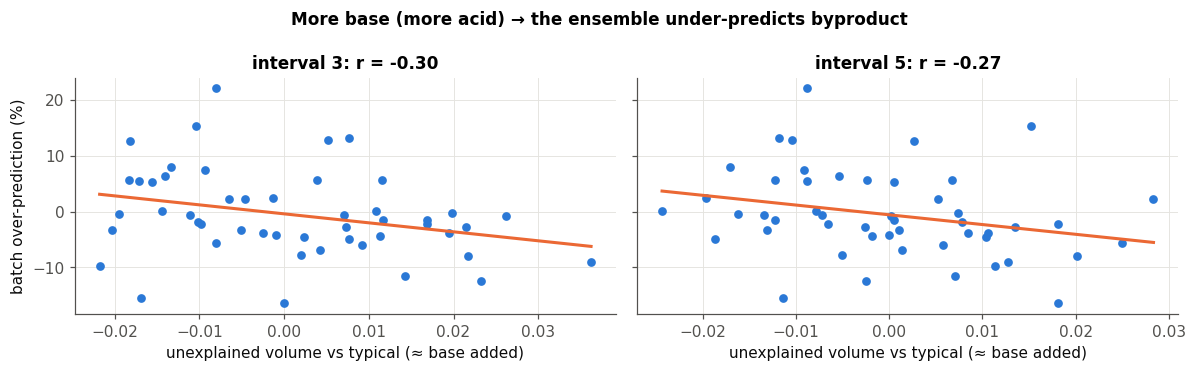

In [9]:
offsets = cv.batch_offsets(T, before_offset).groupby(level=1).mean()
plots.plot_base_offset(base, offsets);

The correlation is real but modest (r ≈ −0.3). Batches that received more base on days 3–5 have more byproduct than the ensemble predicts. Section 7 turns this into a small batch-level correction.

A third candidate, the Feed B dose, turned out to follow the volume schedule rather than the cells, so it is a plan, not a sensor. Not every input is a controller output, and you have to check.

## 5. Cell densities: a kinetic model blended with a teammate ensemble

### 5.1 The kinetic model "v4" (mechanistic + ML hybrid)

Mass balances give the *shape* of the trajectories; machine learning corrects what the simple physics misses.

**Viable cells.** All batches share a time-varying specific growth rate $g(t)$, a smooth B-spline. Cumulative feeds shift growth:

$$X_v(t) = X_{v,0}^{\text{eff}} \exp\!\Big(\int_0^t g(s)\,ds + \beta^\top F(t)\Big)$$

The measured day-0 VCD is noisy, so the effective start is shrunk toward the population: $\log X^{\text{eff}}_{v,0} = a + b \log X_{v,0}$ with $b<1$. About half of a batch's day-0 deviation turns out to be measurement noise.

**Dead cells, substrate and byproduct** are amounts that change at *per-cell* rates, so more cells mean faster consumption and production:

$$m_k(t) = m_k(0) + \int_0^t q_k(s)\,X_v(s)\,ds + r_k\, t + \gamma_k^\top F(t), \qquad c_k = m_k / V(t).$$

Here $q_k(t)$ is a smooth specific rate and $\gamma_k$ are the feed concentrations. Everything is fitted with relative errors (Section 2a). Tree ensembles (random forest, ExtraTrees with MAPE-weighted absolute error) then model what the ODE gets wrong.

**Stabilising the fit.** v4 is averaged over 10 fits, each on a different 90% of the training batches. Like bagging, this reduces the variance of a nonlinear fit (better than one fit in 13 of 15 CV folds).

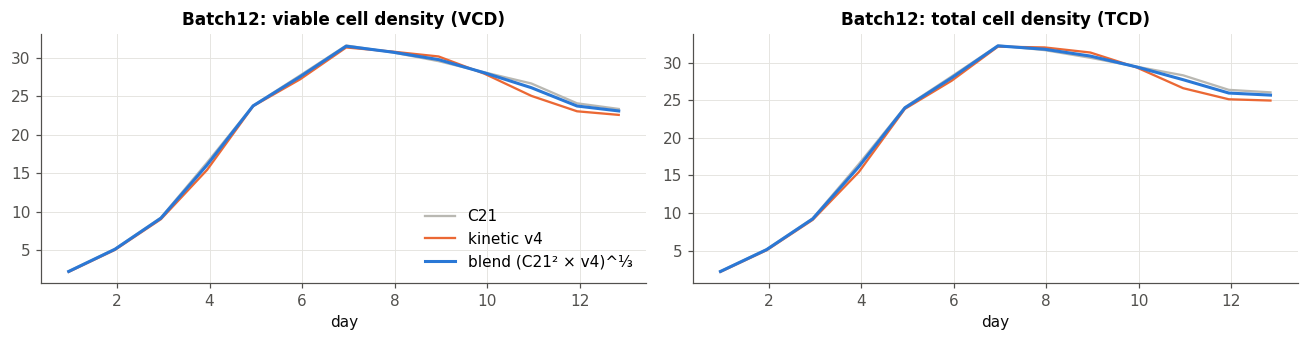

In [10]:
c21, v4 = pipeline.load_c21(), pipeline.load_v4()
cells = pipeline.blend_cells(c21, v4)          # (C21^2 * v4)^(1/3) for VCD and TCD; substrate = C21
plots.plot_cells_blend(c21, v4, cells, "Batch12");

### 5.2 The blend

**C21** is the team's per-target ensemble, built by teammates on the C11 library (learned-rate hybrids, ExtraTrees and random forests). Here it is an input file. For VCD and TCD, we add v4 as an extra member in a weighted **geometric** mean:

$$\widehat{\text{VCD}} = \big(\text{C21}^2 \cdot \text{v4}\big)^{1/3}.$$

Why does adding a weaker model help? Ensemble error = average member error − diversity (the ambiguity decomposition). v4 is a mechanistic model whose mistakes are different from those of tree-based ensembles, so averaging cancels part of the error. Weight 1/4 was validated in CV (VCD −0.045, TCD −0.033) and improved the leaderboard from 7.105 to 7.043. Raising it to 1/3 improved the leaderboard again (to 6.995). That step could not be cross-validated, because there are no out-of-fold C21 predictions, and Section 3 says to treat it with caution.

Substrate is C21 unchanged.

## 6. Byproduct: a six-member ensemble

Byproduct is the hardest target (largest error). It is forecast by six members with deliberately different structures:

| Member | Model | Idea |
|---|---|---|
| **B1, B2** | mean daily curve × exp(ridge correction of the log residual, one ridge per day) | a strong, simple baseline. Inputs: day-0 state, feed design, look-ahead feed doses, volume residuals (B2 adds the base-volume profile) |
| **C** | ExtraTrees on the log deviation from the daily mean curve | nonlinear interactions between inputs |
| **K4, K6** | whole-curve (functional) regression | see below; knots every 2.5 and 2 days |
| **A6** | whole-curve regression on the **amount** (byproduct × volume), divided by the volume | removes dilution by feeds |

**Whole-curve regression (function-on-scalar).** Instead of predicting each day separately, each training batch's log-byproduct curve is summarised by a few B-spline coefficients. These are fitted with shrinkage toward the pooled curve, so noisy batches are not over-fitted. A ridge regression then maps batch inputs (day-0 state, feed design, base-volume profile, controller dose bits) to those coefficients. The forecast is smooth and physically coherent across days, which complements the per-day models.

**Amount instead of concentration.** Feeding adds volume and dilutes the byproduct: $c = m/V$. The produced amount $m$ follows the culture's metabolism and is smoother. Modelling $\log(cV)$ and then dividing by the known test volume puts the mass balance into the model.

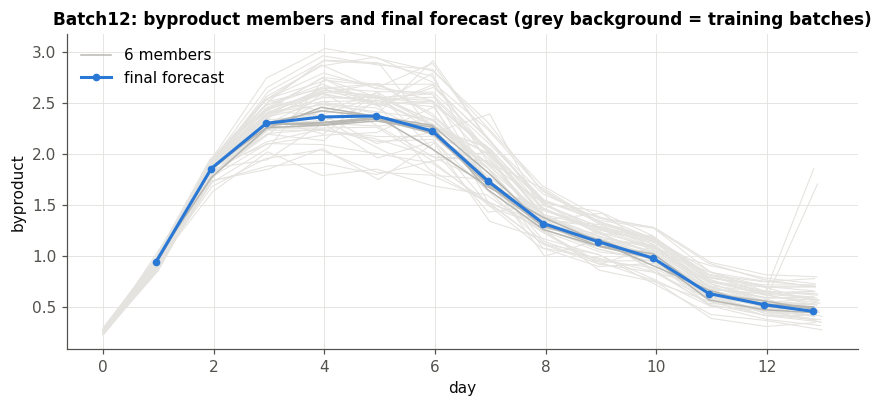

In [11]:
key = pipeline.byproduct_members()             # 6 members fitted on all 49 training batches (~15 s)
day13_shift, offset = pipeline.corrections()   # learned from out-of-fold errors, see Section 7
byp = pipeline.byproduct_forecast(key, day13_shift, offset)
plots.plot_members(byp, raw, "Batch12");

## 7. Two corrections learned from out-of-fold errors

Out-of-fold errors are the model's honest mistakes. If they are *systematic*, they can be learned and removed, but only with nested validation (Section 3).

### 7.1 The day-13 bias: robust statistics

Two training batches (Batch29 and Batch34) triple their byproduct on the last day, and no input predicts it. The per-day models average over batches, so these two points pull *every* batch's day-13 forecast up by about 6%:

correction learned on all training batches: day-13 forecasts × exp(-0.0582) = × 0.943


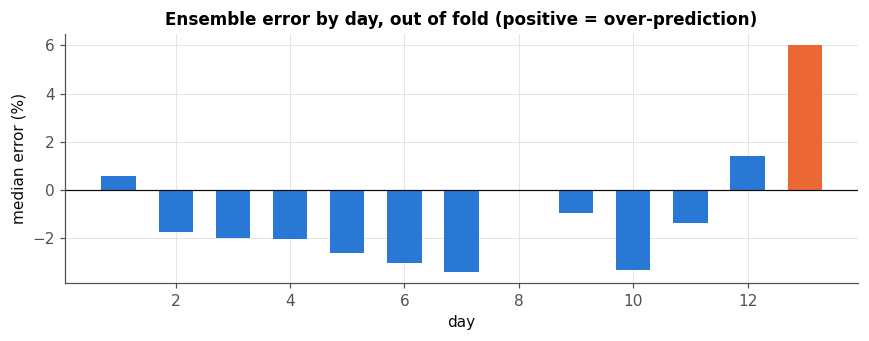

In [12]:
pre = cv.geo(T, cv.C11 + cv.CURVES + cv.AMOUNT)
plots.plot_daily_bias(T, pre, "Ensemble error by day, out of fold (positive = over-prediction)")
print(f"correction learned on all training batches: day-13 forecasts × exp(-{day13_shift:.4f}) = × {np.exp(-day13_shift):.3f}")

Day 13 stands out. On the other days the ensemble sits slightly *below* the measured values (−1 to −3%). That is what Section 2c predicts for a MAPE-oriented forecast, and per-day corrections for those days made CV worse. We remove the **median** day-13 log error, which is robust to the two outliers (the mean would be dragged by them). CV: 8.66 → 8.55.

### 7.2 The batch offset: a random effect we can only partly predict

Write the log error of batch $b$ at time $t$ as

$$\log \hat y_{bt} - \log y_{bt} = u_b + \varepsilon_{bt},$$

where $u_b$ is a batch-level offset (a *random effect* in mixed-model language) and $\varepsilon_{bt}$ is the rest. How much of the error is $u_b$, and what would knowing it be worth?

In [13]:
share, oracle = cv.variance_decomposition(T, before_offset)
print(f"batch-level share of the log-error variance: {100 * share:.0f}%")
print(f"byproduct CV MAPE now: {table.loc['+ amount curve (A6)', 'CV MAPE']:.2f}  →  if u_b were known: {oracle:.2f}")

batch-level share of the log-error variance: 34%
byproduct CV MAPE now: 8.50  →  if u_b were known: 6.64


About a third of the error is a single number per batch: the batch's overall metabolic level. An oracle that knew it would reach the leaders' range. For a test batch, though, we only see day 0, and $u_b$ must be predicted from inputs. The base volume (Section 4.2) is the only input that tracks it.

We fit a ridge regression of $u_b$ on the base added in intervals 3 and 5, using out-of-fold offsets of the training batches, and apply it at **half strength**: $\hat y \leftarrow \hat y \cdot e^{-0.5\,\hat u_b}$. Half strength is shrinkage: the predictor is weak (it explains roughly 12–15% of $u_b$), and applying a noisy estimate at full strength adds variance. CV: 8.50 → 8.42. This was chosen among 24 variants, so the true gain is probably smaller.

The adjustment for each test batch is small:

In [14]:
(100 * (np.exp(-pipeline.OFFSET_STRENGTH * offset) - 1)).round(2).to_frame("byproduct change (%)").T

,Batch12,Batch24,Batch32,Batch35,Batch40,Batch48,Batch5,Batch54,Batch56,Batch57,Batch6,Batch60
byproduct change (%),0.9,-0.08,0.36,-0.62,-1.36,1.7,-0.3,0.66,-1.02,1.03,-0.01,-0.83


## 8. The final forecast

Assemble the targets and check that the result equals the submitted file:

largest difference vs the submitted file (%): vcd 2.0e-14, tcd 1.9e-14, substrate 0.0e+00, byproduct 4.0e-14


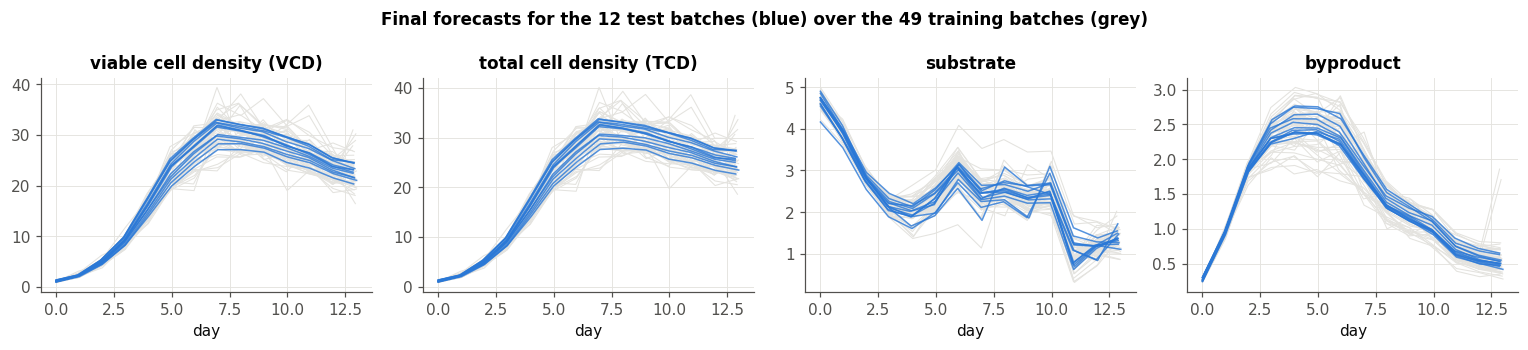

In [15]:
final = pipeline.assemble(cells, byp)
final.to_csv("final_6995.csv", index=False)
diff = pipeline.compare_to_submitted(final)
print("largest difference vs the submitted file (%):", ", ".join(f"{t} {d:.1e}" for t, d in zip(["vcd", "tcd", "substrate", "byproduct"], diff)))
plots.plot_test_forecasts(final, raw);

## 9. Results

### 9.1 Byproduct, step by step (team CV, nested, paired per batch)

,CV MAPE,change,± SE,% batches better
step,,,,
"C11 members (B1, B2, C)",8.922,NaN,NaN,NaN
"+ 2 whole-curve members (K4, K6)",8.658,-0.264,0.083,61.224
+ day-13 correction,8.549,-0.109,0.043,56.122
+ amount curve (A6),8.500,-0.050,0.022,62.245
+ base-volume batch offset (final),8.423,-0.077,0.056,60.204


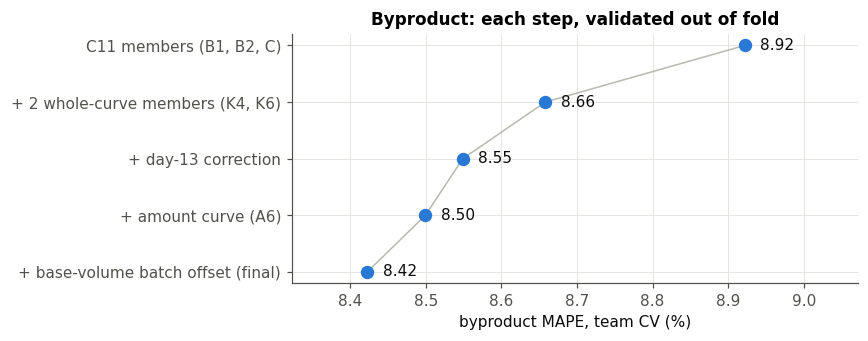

In [16]:
display(table.round(3))
plots.plot_ablation(table);

Every step improves the CV score in a majority of batches, and the gains shrink as we go. The first structural idea (whole-curve members) is worth more than all later corrections combined.

### 9.2 Leaderboard history

,version,idea,leaderboard MAPE
0,v1,random forest + kinetic ODE,8.251
1,C9,per-target ensembles + controller features,7.321
2,C21 + curves,teammate C21 + whole-curve byproduct members,7.105
3,+ v4 cells,kinetic v4 as a VCD/TCD member (weight 1/4),7.043
4,+ day 13,remove day-13 byproduct over-prediction,7.026
5,+ amount curve,"byproduct curve fitted on amount, not concentr...",7.019
6,+ base offset,batch-level byproduct correction from base volume,7.008
7,final,v4 weight 1/3 for VCD/TCD,6.995


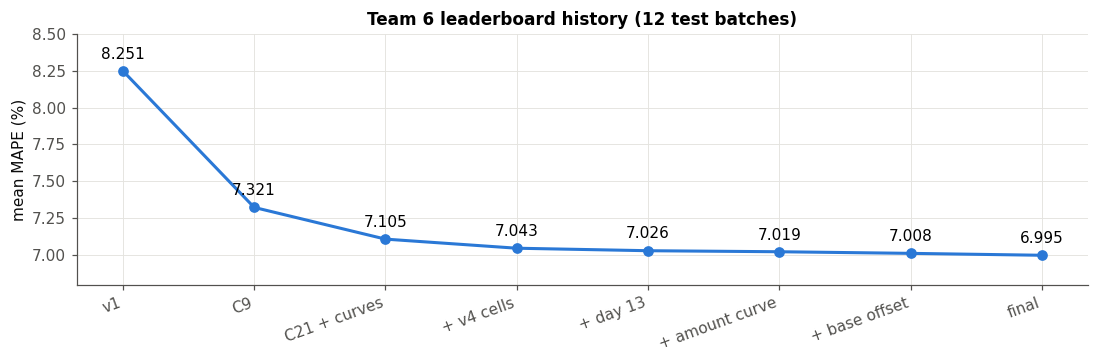

In [17]:
display(pipeline.LEADERBOARD)
plots.plot_leaderboard(pipeline.LEADERBOARD);

The big early drop came from training on the metric, using the controller signals and building per-target ensembles. The late steps are each smaller than the 12-batch leaderboard noise estimated in Section 3.

## 10. What did not work (and why that is useful)

The full log is in `docs/RESEARCH_LOG.md`. A selection:

| Idea | Outcome | Lesson |
|---|---|---|
| Physics-informed neural network (PINN) for byproduct | looked great on the fixed benchmark (8.10), worse in full CV (12.5 alone; ensemble worse in 10/10 folds) | a small fixed benchmark can mislead |
| Byproduct mass balance using the base volume | no gain over the ensemble | a correct mechanism is not automatically new information |
| Stacking with learned member weights | lopsided, unstable weights, no gain | with 49 batches, equal weights are hard to beat |
| Gaussian processes / trees on the residuals | worse in nested CV | residuals are mostly unpredictable noise + batch offset |
| Local (nearest-neighbour) training | worse | neighbourhoods of 5–12 batches are too noisy |
| Per-day bias corrections (other than day 13) | worse | only correct a bias you can explain |
| Explicit MAPE down-scaling (Section 2c) | no gain | the ensemble was already unbiased in the MAPE sense |
| Feed B and feed C timing as sensors | no signal | check before you assume an input is a controller output |

### Takeaways for ML in pharma process development

1. **Let the metric drive the design**: loss, ensemble averaging and point forecast.
2. **Validate like the deployment.** Hold out whole batches, repeat the splits, compare in pairs, nest everything you tune, and distrust small test sets.
3. **Read the control system.** Feed and pH controller decisions are measurements in disguise, and they are often the most informative inputs.
4. **Physics for structure, ML for the rest.** Kinetic and mass-balance models give the right shape and extrapolate sensibly; tree ensembles capture what they miss; diverse members average well.
5. **Know what is missing.** A third of the byproduct error is a batch-level metabolic offset that no input records. Better models will not fix that; an extra early measurement (lactate or pH on day 2–3) would. This is a concrete recommendation for the experimental design, not only for the model.

## 11. Exercises

1. **Metric.** Use `metrics.best_constants` on day-11 substrate. How far is the MAPE-optimal constant from the mean? Why is the gap larger than for day-1 VCD?
2. **Ensemble weights.** Change `pipeline.blend_cells(c21, v4, w_c21=...)` to weights 1, 2, 3 and 5. How much do the VCD forecasts move? Why can't you choose the weight by cross-validation here?
3. **Members.** In Section 9, recompute the CV MAPE of the byproduct ensemble without each member (`cv.geo(T, members)` and `metrics.per_batch`). Which member matters most? Is it also the best member on its own?
4. **Offset strength.** In `cv.base_offset_nested`, vary `strength` between 0 and 1. Plot CV MAPE against strength. Does the optimum depend on the split?
5. **Leaderboard noise.** Use `cv.leaderboard_noise` to estimate how many test batches you would need before a 0.05 improvement becomes detectable.
6. **Experimental design.** Suppose you could measure byproduct on day 2 in the test batches. Using the variance decomposition, estimate the best achievable byproduct MAPE. What would you tell the process development team?

## 12. Submission (optional)

Every call is a real, counted leaderboard attempt.

In [18]:
SUBMIT = False
if SUBMIT:
    print(pipeline.submit("final_6995.csv"))